# Ariketa 2.8 — Fluxu osoa zerotik, beste dataset batekin

Bete `# TODO` markatutako gelaxkak. Titanic-eko jarduerak dituzu erreferentzia gisa.

## 0. Prestaketa eta karga

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

pg = sns.load_dataset('penguins')
pg.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## 1. EDA — datuei begiratu

*Iragarri nahi duguna:* `species` (pinguino-espeziea) -> hori izango da **y**.

In [2]:
# Forma, info, describe eta nuluak (print/display bakoitzarekin, denak ikusteko)
print('Forma:', pg.shape)
pg.info()
display(pg.describe())
print('Nuluak:')
print(pg.isnull().sum())
print('\nEspezieak:')
print(pg['species'].value_counts())

Forma: (344, 7)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Nuluak:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Espezieak:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


## 2. Aldagai motak eta X / y

**Pentsatu:** zein dira numerikoak, zein kategorikoak, zein da etiketa (y)?

In [3]:
# Numerikoak
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
# Kategorikoak (X-en sartuko direnak): nominalak
cat_cols = ["island", "sex"]
# Etiketa (y): kategorikoa ere bada, baina X-etik kanpo
target = "species"

## 3. Balio faltak (inputazioa)

Numerikoak: mediana. Kategorikoa (`sex`): moda. *(Gogoratu: emaitza aldagai bati esleitu!)*

In [4]:
# Kopia bat egin jatorrizkoa ez aldatzeko
p = pg.copy()
# Numerikoak: mediana (emaitza p-ri ESLEITU)
p[num_cols] = p[num_cols].fillna(p[num_cols].median())
# Kategorikoa (sex): moda
p["sex"] = p["sex"].fillna(p["sex"].mode()[0])
# Egiaztatu ez dagoela nulurik
print('Nulurik ez:', p.isnull().sum().sum() == 0)

Nulurik ez: True


## 4. Outlierrak (aukerakoa: begiratu)

Begiratu numeriko baten boxplot-a. Pinguinoetan ez dago outlier larririk, baina ohitura ona da begiratzea.

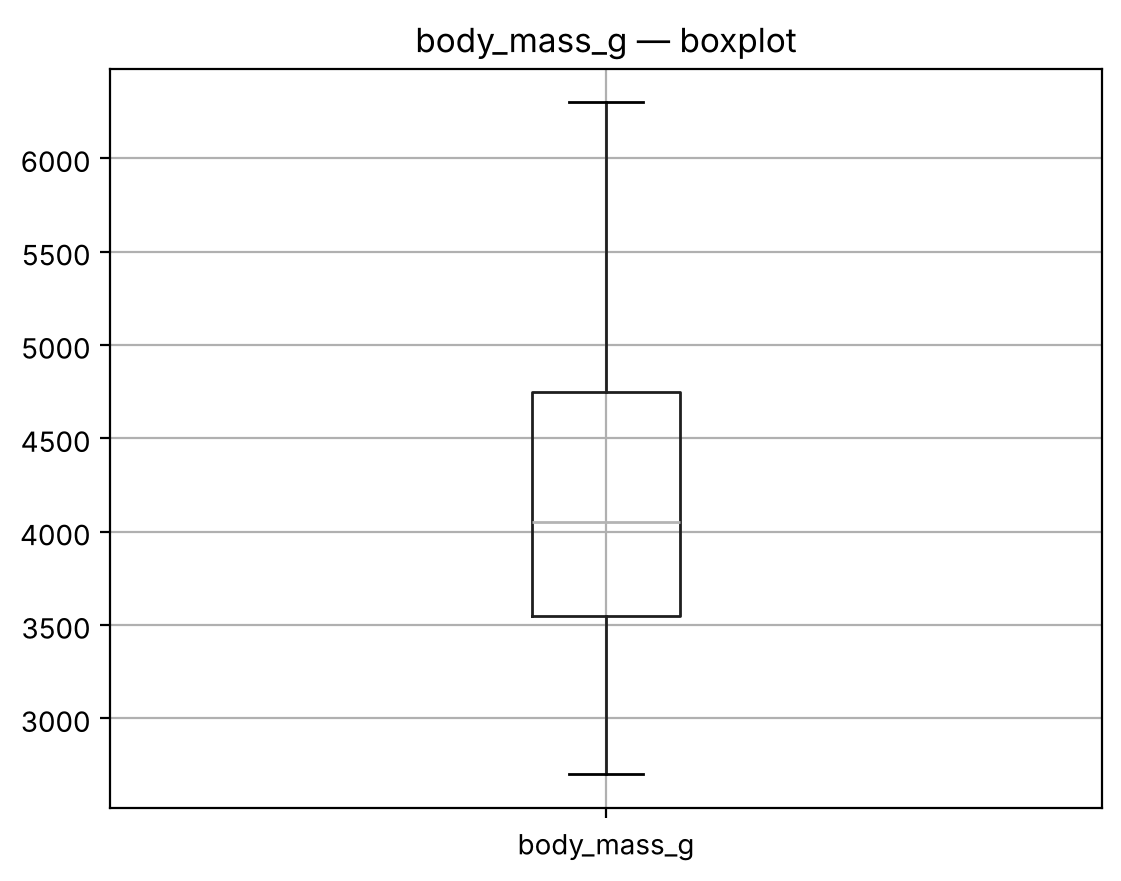

bill_length_mm     mugak [25.4, 62.3] -> outlierrak: 0
bill_depth_mm      mugak [10.9, 23.3] -> outlierrak: 0
flipper_length_mm  mugak [155.5, 247.5] -> outlierrak: 0
body_mass_g        mugak [1750.0, 6550.0] -> outlierrak: 0


In [5]:
# body_mass_g-ren boxplot-a
p.boxplot(column="body_mass_g")
plt.title("body_mass_g — boxplot")
plt.show()

# IQR-outlierrak numeriko guztietan
for col in num_cols:
    Q1, Q3 = p[col].quantile(0.25), p[col].quantile(0.75)
    IQR = Q3 - Q1
    low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((p[col] < low) | (p[col] > high)).sum()
    print(f"{col:18s} mugak [{low:.1f}, {high:.1f}] -> outlierrak: {n_out}")

**Ondorioa:** IQR irizpidearekin ez dago outlierrik aldagai numerikoetan (0 guztietan) → ez da capping edo log-transformaziorik behar.

## 5. Encoding — X (one-hot) eta y (label)

`species` (y) -> label. `island`, `sex` (X) -> one-hot (nominalak).

In [6]:
from sklearn.preprocessing import LabelEncoder

# y: species -> label (Adelie=0, Chinstrap=1, Gentoo=2)
le = LabelEncoder()
y = le.fit_transform(p[target])
print('Klaseak:', list(le.classes_))

# X: gainerakoak; island eta sex -> one-hot (nominalak)
X = pd.get_dummies(p.drop(columns=[target]), columns=cat_cols, drop_first=True).astype(float)
print('X shape:', X.shape)
X.head()

Klaseak: ['Adelie', 'Chinstrap', 'Gentoo']
X shape: (344, 7)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_Male
0,39.10,18.7,181.0,3750.0,0.0,1.0,1.0
1,39.50,17.4,186.0,3800.0,0.0,1.0,0.0
2,40.30,18.0,195.0,3250.0,0.0,1.0,0.0
3,44.45,17.3,197.0,4050.0,0.0,1.0,1.0
4,36.70,19.3,193.0,3450.0,0.0,1.0,0.0


## 6. Train / test banaketa (stratify!)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
# Proportzioak bietan antzekoak direla egiaztatu
print('Train proportzioak:', np.bincount(y_train) / len(y_train))
print('Test proportzioak :', np.bincount(y_test) / len(y_test))

Train: (275, 7) | Test: (69, 7)
Train proportzioak: [0.44363636 0.19636364 0.36      ]
Test proportzioak : [0.43478261 0.20289855 0.36231884]


## 7. Feature scaling — SOILIK train-arekin doituta

Numerikoak bakarrik eskalatu (ez one-hot dummyak). `fit` train-ekin; `transform` bietan.

In [8]:
from sklearn.preprocessing import StandardScaler

X_train = X_train.copy()
X_test = X_test.copy()

sc = StandardScaler()
# fit_transform SOILIK train-ean (num_cols bakarrik, dummyak ez)
X_train[num_cols] = sc.fit_transform(X_train[num_cols])
# test-ean transform bakarrik (train-en media/std-ekin)
X_test[num_cols] = sc.transform(X_test[num_cols])

print('Train batez (~0):', X_train[num_cols].mean().round(2).values)
print('Test batez      :', X_test[num_cols].mean().round(2).values)
X_train.head()

Train batez (~0): [-0. -0.  0.  0.]
Test batez      : [-0.13 -0.05  0.03 -0.06]


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_Male
98,-2.005582,-0.534871,-1.642552,-1.634638,1.0,0.0,0.0
114,-0.817283,1.761064,-0.706755,-0.386909,0.0,0.0,0.0
118,-1.530262,-0.085667,-0.850724,-1.073160,0.0,1.0,0.0
303,1.083994,-0.634694,1.668728,1.422297,0.0,0.0,1.0
343,1.065713,-0.534871,0.876900,1.484684,0.0,0.0,1.0


## 8. Prest!

Amaitu duzunean, datuak modelizatzeko prest egon behar dute. Alderatu zure emaitza Titanic-eko fluxuarekin.

**Alderaketa Titanic-eko fluxuarekin:** pauso berak dira (EDA → motak → inputazioa → outlierrak → encoding → split → scaling). Desberdintasunak: hemen helburua **3 klaseko** sailkapena da (Titanic-en binarioa), eta y `LabelEncoder`-ekin kodetzen da.

> Oharra: ariketak eskatzen duen ordenari jarraitu diogu (inputazioa split-aren aurretik). Modu zorrotzean, mediana eta moda **train-etik bakarrik** kalkulatu beharko lirateke split-aren ondoren, data leakage saihesteko (3.x notebook-etan egiten den bezala).